In [ ]:
!pip install hmmlearn
import numpy as np
import hmmlearn as hmm
from hmmlearn import hmm
import matplotlib.pyplot as plt
import networkx as nx

In [ ]:
model = hmm.CategoricalHMM(n_components=3, init_params="")
model.startprob_ = np.array([1/3, 1/3, 1/3])
model.transmat_ = np.array([[0, 1/2, 1/2],
                           [1/2, 1/4, 1/4],
                           [1/2, 1/4, 1/4]])
model.emissionprob_ = np.array([[0.1, 0.2, 0.4, 0.3],
                               [0.15, 0.25, 0.5, 0.1],
                               [0.2, 0.3, 0.4, 0.1]])
model.n_features = 4

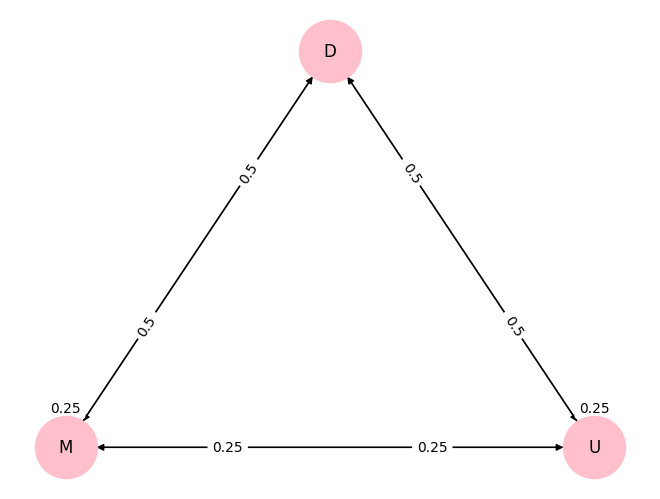

In [ ]:
difficulty = ["D", "M", "U"]

G = nx.DiGraph()
for i in range(3):
    for j in range(3):
        if model.transmat_[i][j] > 0:
            G.add_edge(difficulty[i], difficulty[j], weight=model.transmat_[i][j])

pos = {"D": (0, 1), "M": (-1, 0), "U": (1, 0)}
nx.draw(G, pos, with_labels=True, node_size=2000, node_color="pink")
nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "weight"), label_pos=0.3)

plt.show()

In [ ]:
sequence = np.array([[0], [0], [2], [1], [1], [2], [1], [1], [3], [1], [1], [2]])

logProb, viterbi = model.decode(sequence)

print([difficulty[v] for v in viterbi])

print(np.exp(logProb))

['U', 'U', 'D', 'U', 'D', 'M', 'D', 'U', 'D', 'U', 'D', 'M']
2.109375000000024e-11
